In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

# Display first 5 rows
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
#Explore the dataset
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Number of rows and columns:
(5110, 12)

Column names:
Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11 

In [3]:
print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (5110, 12)

Column names:
Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke      

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [5]:
#Check missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Duplicate rows:
0


In [6]:
#Fill missing BMI values and remove duplicates:
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

df = df.drop_duplicates()

print(df.isnull().sum())

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


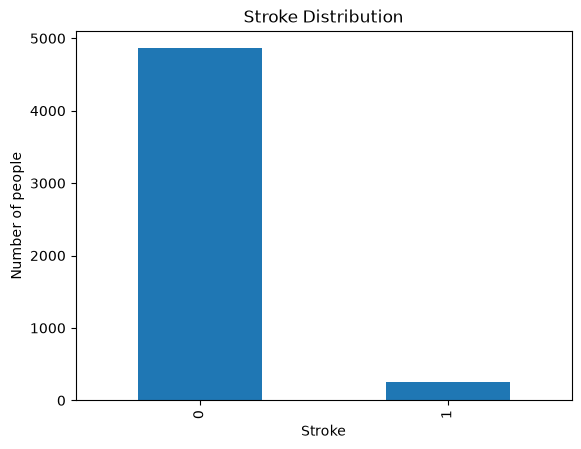

In [7]:
#Data visualisation: 1. Stroke distribution
df["stroke"].value_counts().plot(
    kind="bar",
    title="Stroke Distribution"
)

plt.xlabel("Stroke")
plt.ylabel("Number of people")
plt.show()

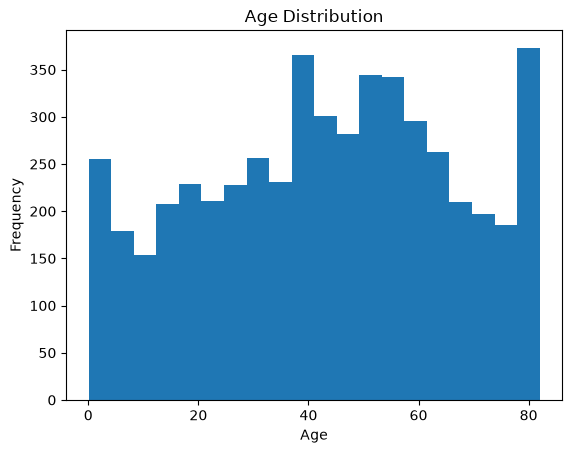

In [8]:
# 2. Age distribution
plt.hist(df["age"], bins=20)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

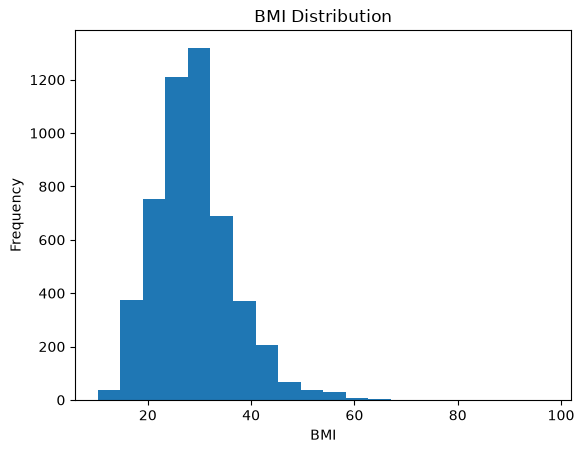

In [9]:
# 3.BMI distribution
plt.hist(df["bmi"], bins=20)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()

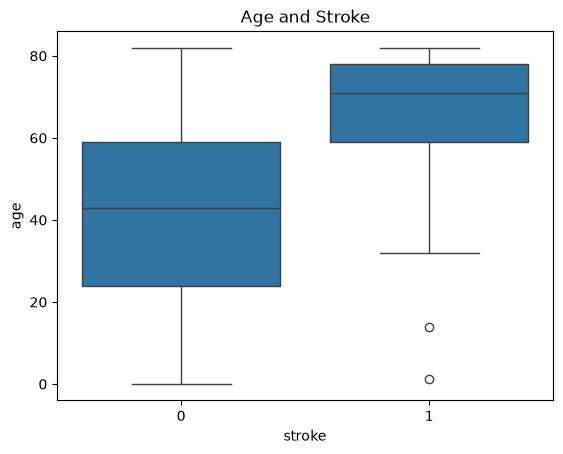

In [10]:
# 4. Relationship between age and stroke
sns.boxplot(x="stroke", y="age", data=df)

plt.title("Age and Stroke")
plt.show()

In [11]:
#Data preprocessing": Convert categorical variables into numerical variables
df = df.drop(columns=["id"])

df = pd.get_dummies(
    df,
    columns=[
        "gender",
        "ever_married",
        "work_type",
        "Residence_type",
        "smoking_status"
    ],
    drop_first=True
)

df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,False,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,28.1,1,False,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.5,1,True,False,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.4,1,False,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.0,1,False,False,True,False,False,True,False,False,False,True,False


In [12]:
#Define X and Y
#- X = Independent variables (features).
#- Y = Dependent variable (target variable).
X = df.drop("stroke", axis=1)

Y = df["stroke"]

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (5110, 16)
Y shape: (5110,)


In [13]:
#Split data into training and testing
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3832, 16)
Testing data: (1278, 16)


In [14]:
#Feature scaling
#StandardScaler is used to scale the features for SVM and PCA.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [15]:
#Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, Y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Results")

print("Accuracy:", accuracy_score(Y_test, rf_predictions))
print("Precision:", precision_score(Y_test, rf_predictions))
print("Recall:", recall_score(Y_test, rf_predictions))
print("F1 Score:", f1_score(Y_test, rf_predictions))

print(classification_report(Y_test, rf_predictions))

Random Forest Results
Accuracy: 0.9374021909233177
Precision: 0.2
Recall: 0.0967741935483871
F1 Score: 0.13043478260869565
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1216
           1       0.20      0.10      0.13        62

    accuracy                           0.94      1278
   macro avg       0.58      0.54      0.55      1278
weighted avg       0.92      0.94      0.93      1278



In [16]:
#Support Vector Machine (SVM)
svm_model = SVC(
    kernel="rbf",
    C=1,
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_scaled, Y_train)

svm_predictions = svm_model.predict(X_test_scaled)

print("SVM Results")

print("Accuracy:", accuracy_score(Y_test, svm_predictions))
print("Precision:", precision_score(Y_test, svm_predictions))
print("Recall:", recall_score(Y_test, svm_predictions))
print("F1 Score:", f1_score(Y_test, svm_predictions))

print(classification_report(Y_test, svm_predictions))

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Results
Accuracy: 0.7629107981220657
Precision: 0.12461059190031153
Recall: 0.6451612903225806
F1 Score: 0.20887728459530025
              precision    recall  f1-score   support

           0       0.98      0.77      0.86      1216
           1       0.12      0.65      0.21        62

    accuracy                           0.76      1278
   macro avg       0.55      0.71      0.53      1278
weighted avg       0.94      0.76      0.83      1278



In [17]:
#GridSearchCV – Find the best SVM parameters
svm_parameters = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

grid_search = GridSearchCV(
    SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    ),
    svm_parameters,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, Y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best CV F1 Score:")
print(grid_search.best_score_)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters:
{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Best CV F1 Score:
0.2263454770422631


In [18]:
#Train and evaluate the best SVM model:
best_svm = grid_search.best_estimator_

best_predictions = best_svm.predict(X_test_scaled)

print(classification_report(Y_test, best_predictions))

              precision    recall  f1-score   support

           0       0.99      0.71      0.83      1216
           1       0.12      0.79      0.21        62

    accuracy                           0.72      1278
   macro avg       0.55      0.75      0.52      1278
weighted avg       0.94      0.72      0.80      1278



In [19]:
#Cross-validation: Compare Random Forest and SVM using 5-fold cross-validation
rf_cv = cross_val_score(
    rf_model,
    X,
    Y,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

svm_cv = cross_val_score(
    SVC(
        kernel="rbf",
        class_weight="balanced"
    ),
    X_train_scaled,
    Y_train,
    cv=5,
    scoring="f1"
)

print("Random Forest CV scores:", rf_cv)
print("Random Forest average:", rf_cv.mean())

print("SVM CV scores:", svm_cv)
print("SVM average:", svm_cv.mean())

Random Forest CV scores: [0.07594937 0.09638554 0.02702703 0.20512821 0.02941176]
Random Forest average: 0.08678038122367936
SVM CV scores: [0.18852459 0.22413793 0.19004525 0.21524664 0.1980198 ]
SVM average: 0.20319484176373875


In [20]:
#Compare 5%, 15%, and 25% test splits
test_sizes = [0.05, 0.15, 0.25]

results = []

for size in test_sizes:

    X_train, X_test, Y_train, Y_test = train_test_split(
        X,
        Y,
        test_size=size,
        random_state=42,
        stratify=Y
    )

    # Random Forest
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    )

    rf.fit(X_train, Y_train)

    rf_pred = rf.predict(X_test)

    # SVM
    scale = StandardScaler()

    X_train_s = scale.fit_transform(X_train)
    X_test_s = scale.transform(X_test)

    svm = SVC(
        kernel="rbf",
        class_weight="balanced"
    )

    svm.fit(X_train_s, Y_train)

    svm_pred = svm.predict(X_test_s)

    results.append({
        "Test Size": str(int(size * 100)) + "%",
        "RF Accuracy": accuracy_score(Y_test, rf_pred),
        "RF Recall": recall_score(Y_test, rf_pred),
        "RF F1": f1_score(Y_test, rf_pred),
        "SVM Accuracy": accuracy_score(Y_test, svm_pred),
        "SVM Recall": recall_score(Y_test, svm_pred),
        "SVM F1": f1_score(Y_test, svm_pred)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Test Size,RF Accuracy,RF Recall,RF F1,SVM Accuracy,SVM Recall,SVM F1
0,5%,0.937500,0.083333,0.111111,0.800781,0.416667,0.163934
1,15%,0.932203,0.081081,0.103448,0.769231,0.594595,0.199095
2,25%,0.937402,0.096774,0.130435,0.762911,0.645161,0.208877


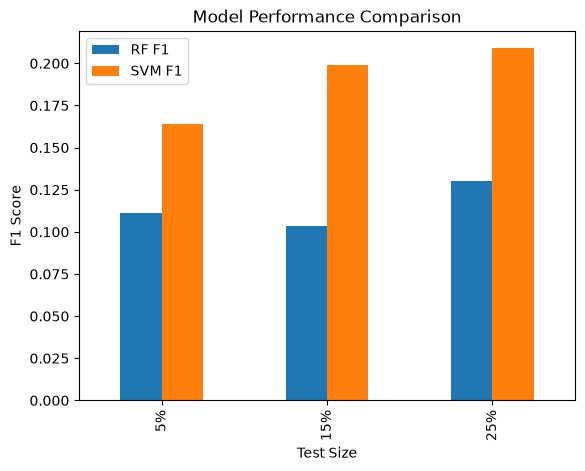

In [21]:
#Visualise the comparison:
results_df.plot(
    x="Test Size",
    y=["RF F1", "SVM F1"],
    kind="bar"
)

plt.title("Model Performance Comparison")
plt.ylabel("F1 Score")
plt.show()

In [22]:
#PCA – Dimensionality Reduction: PCA reduces the number of features while keeping as much information as possible.
pca = PCA()

X_pca = pca.fit_transform(X_train_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained variance:")
print(explained_variance)

print("Total explained variance:")
print(sum(explained_variance))

Explained variance:
[0.1876822  0.10575729 0.08850288 0.07331352 0.0723211  0.06476278
 0.0628015  0.05988543 0.05843337 0.05521345 0.05102951 0.04285306
 0.03154605 0.01888478 0.01616109 0.01085199]
Total explained variance:
1.0


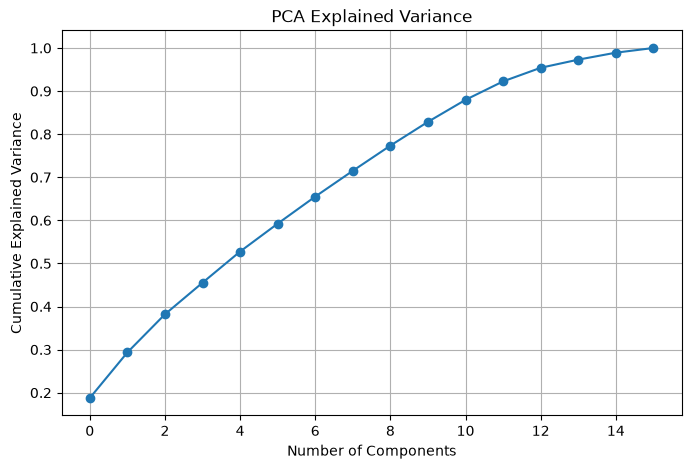

In [23]:
#Visualise explained variance:
plt.figure(figsize=(8, 5))

plt.plot(
    np.cumsum(explained_variance),
    marker="o"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.grid()
plt.show()

In [24]:
#Select components that explain 95% of the variance:
pca_95 = PCA(n_components=0.95)

X_train_pca = pca_95.fit_transform(X_train_scaled)

X_test_pca = pca_95.transform(X_test_scaled)

print("Original features:", X_train.shape[1])

print("Reduced features:", X_train_pca.shape[1])

Original features: 16
Reduced features: 13


In [25]:
#Train SVM using PCA:
pca_svm = SVC(
    kernel="rbf",
    class_weight="balanced"
)

pca_svm.fit(X_train_pca, Y_train)

pca_predictions = pca_svm.predict(X_test_pca)

print("PCA + SVM Results")

print(classification_report(Y_test, pca_predictions))

PCA + SVM Results
              precision    recall  f1-score   support

           0       0.98      0.76      0.86      1216
           1       0.12      0.63      0.20        62

    accuracy                           0.76      1278
   macro avg       0.55      0.70      0.53      1278
weighted avg       0.93      0.76      0.83      1278



In [26]:
#Feature Importance – Random Forest: Identify the most important features for stroke prediction.
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
0,age,0.379673
3,avg_glucose_level,0.199880
4,bmi,0.180759
7,ever_married_Yes,0.037854
1,hypertension,0.027475
2,heart_disease,0.023812
5,gender_Male,0.022811
12,Residence_type_Urban,0.021937
14,smoking_status_never smoked,0.020008
9,work_type_Private,0.017907


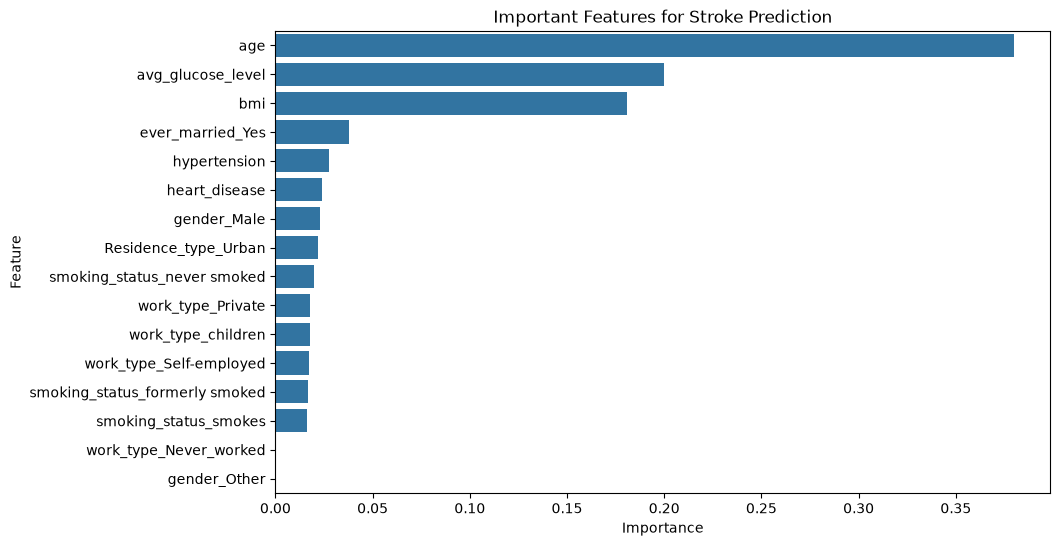

In [27]:
#Visualise feature importance:
plt.figure(figsize=(10, 6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title("Important Features for Stroke Prediction")
plt.show()

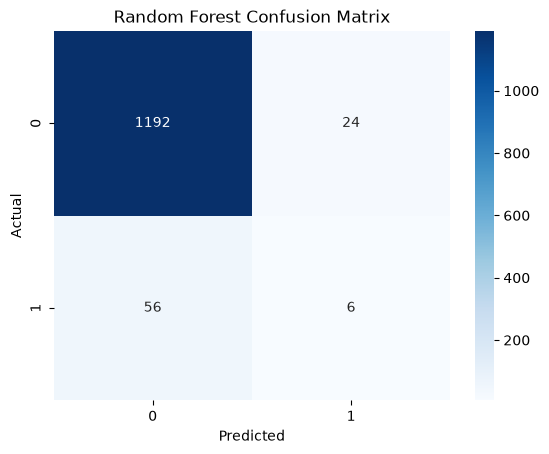

In [28]:
#Confusion Matrix: Random Forest
cm = confusion_matrix(Y_test, rf_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

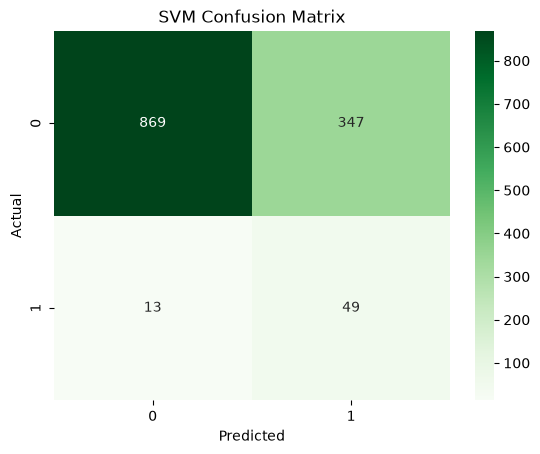

In [29]:
#SVM
cm_svm = confusion_matrix(Y_test, best_predictions)

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("SVM Confusion Matrix")

plt.show()

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


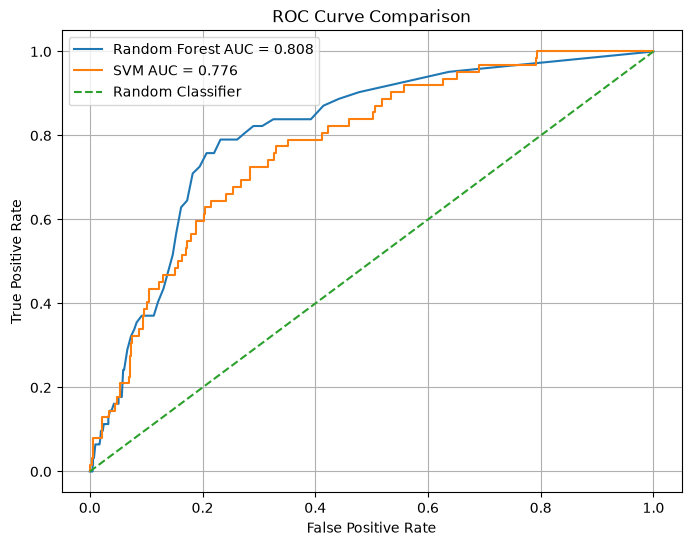

Random Forest AUC: 0.808
SVM AUC: 0.776


In [40]:
#ROC Curve

# Create a new 25% train-test split
from sklearn.metrics import roc_curve, auc
X_train_final, X_test_final, Y_train_final, Y_test_final = train_test_split(
    X,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

# Scale the data for SVM

scaler_final = StandardScaler()

X_train_scaled_final = scaler_final.fit_transform(X_train_final)

X_test_scaled_final = scaler_final.transform(X_test_final)


# Train Random Forest

rf_final = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_final.fit(X_train_final, Y_train_final)


# Train SVM

svm_final = SVC(
    kernel="rbf",
    C=1,
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_final.fit(X_train_scaled_final, Y_train_final)


# Get prediction probabilities

rf_probabilities = rf_final.predict_proba(X_test_final)[:, 1]

svm_probabilities = svm_final.predict_proba(X_test_scaled_final)[:, 1]


# Calculate ROC values

rf_fpr, rf_tpr, _ = roc_curve(
    Y_test_final,
    rf_probabilities
)

svm_fpr, svm_tpr, _ = roc_curve(
    Y_test_final,
    svm_probabilities
)


# Calculate AUC

rf_auc = auc(rf_fpr, rf_tpr)

svm_auc = auc(svm_fpr, svm_tpr)


# Plot ROC Curve

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest AUC = {rf_auc:.3f}"
)

plt.plot(
    svm_fpr,
    svm_tpr,
    label=f"SVM AUC = {svm_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

print("Random Forest AUC:", round(rf_auc, 3))
print("SVM AUC:", round(svm_auc, 3))


In [41]:
#Model comparison table: Compare the performance of the three models.
comparison = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "PCA + SVM"],
    "Accuracy": [
        accuracy_score(Y_test, rf_predictions),
        accuracy_score(Y_test, best_predictions),
        accuracy_score(Y_test, pca_predictions)
    ],
    "Precision": [
        precision_score(Y_test, rf_predictions),
        precision_score(Y_test, best_predictions),
        precision_score(Y_test, pca_predictions)
    ],
    "Recall": [
        recall_score(Y_test, rf_predictions),
        recall_score(Y_test, best_predictions),
        recall_score(Y_test, pca_predictions)
    ],
    "F1 Score": [
        f1_score(Y_test, rf_predictions),
        f1_score(Y_test, best_predictions),
        f1_score(Y_test, pca_predictions)
    ]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.937402,0.200000,0.096774,0.130435
1,SVM,0.718310,0.123737,0.790323,0.213974
2,PCA + SVM,0.757433,0.119632,0.629032,0.201031


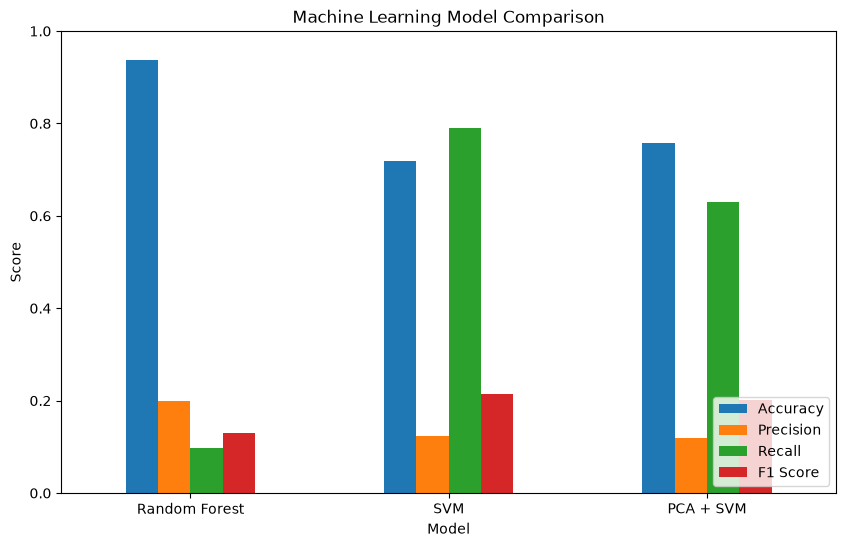

In [42]:
#Visualise model comparison:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [43]:
#Check class imbalance and apply SMOTE: Check the distribution of stroke and non-stroke cases.
print(df["stroke"].value_counts())

print("\nPercentage:")
print(df["stroke"].value_counts(normalize=True) * 100)

stroke
0    4861
1     249
Name: count, dtype: int64

Percentage:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [44]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [45]:
#Apply SMOTE to the training data only:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, Y_train_smote = smote.fit_resample(
    X_train_scaled,
    Y_train
)

print("Before SMOTE:")
print(Y_train.value_counts())

print("\nAfter SMOTE:")
print(Y_train_smote.value_counts())

Before SMOTE:
stroke
0    3645
1     187
Name: count, dtype: int64

After SMOTE:
stroke
0    3645
1    3645
Name: count, dtype: int64


In [46]:
#Train SVM using SMOTE:
smote_svm = SVC(
    kernel="rbf",
    class_weight="balanced"
)

smote_svm.fit(X_train_smote, Y_train_smote)

smote_predictions = smote_svm.predict(X_test_scaled)

print(classification_report(Y_test, smote_predictions))

              precision    recall  f1-score   support

           0       0.97      0.82      0.89      1216
           1       0.11      0.42      0.17        62

    accuracy                           0.81      1278
   macro avg       0.54      0.62      0.53      1278
weighted avg       0.92      0.81      0.85      1278



In [47]:
#Final results
print("FINAL MODEL RESULTS")

print(comparison)

print("\nRandom Forest AUC:", rf_auc)

print("SVM AUC:", svm_auc)

print("\nNumber of PCA components:")
print(X_train_pca.shape[1])

FINAL MODEL RESULTS
           Model  Accuracy  Precision    Recall  F1 Score
0  Random Forest  0.937402   0.200000  0.096774  0.130435
1            SVM  0.718310   0.123737  0.790323  0.213974
2      PCA + SVM  0.757433   0.119632  0.629032  0.201031

Random Forest AUC: 0.8075989494906621
SVM AUC: 0.7761831494057725

Number of PCA components:
13
